<a href="https://colab.research.google.com/github/springboardmentor0702-lgtm/Personalized-TED-Talks-Recommendation-System/blob/Ram-charan/TED_TALKS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
!pip install -q streamlit pandas numpy scikit-learn pyngrok

In [ ]:
import pandas as pd

df = pd.read_csv('//content/drive/MyDrive/Certificate /Ml/ted_talks_en.csv')

In [ ]:
df

,talk_id,title,speaker_1,all_speakers,occupations,about_speakers,views,recorded_date,published_date,event,native_lang,available_lang,comments,duration,topics,related_talks,url,description,transcript
0,1,Averting the climate crisis,Al Gore,{0: 'Al Gore'},{0: ['climate advocate']},{0: 'Nobel Laureate Al Gore focused the world’...,3523392,2006-02-25,2006-06-27,TED2006,en,"['ar', 'bg', 'cs', 'de', 'el', 'en', 'es', 'fa...",272.0,977,"['alternative energy', 'cars', 'climate change...","{243: 'New thinking on the climate crisis', 54...",https://www.ted.com/talks/al_gore_averting_the...,With the same humor and humanity he exuded in ...,"Thank you so much, Chris. And it's truly a gre..."
1,92,The best stats you've ever seen,Hans Rosling,{0: 'Hans Rosling'},{0: ['global health expert; data visionary']},"{0: 'In Hans Rosling’s hands, data sings. Glob...",14501685,2006-02-22,2006-06-27,TED2006,en,"['ar', 'az', 'bg', 'bn', 'bs', 'cs', 'da', 'de...",628.0,1190,"['Africa', 'Asia', 'Google', 'demo', 'economic...","{2056: ""Own your body's data"", 2296: 'A visual...",https://www.ted.com/talks/hans_rosling_the_bes...,You've never seen data presented like this. Wi...,"About 10 years ago, I took on the task to teac..."
2,7,Simplicity sells,David Pogue,{0: 'David Pogue'},{0: ['technology columnist']},{0: 'David Pogue is the personal technology co...,1920832,2006-02-24,2006-06-27,TED2006,en,"['ar', 'bg', 'de', 'el', 'en', 'es', 'fa', 'fr...",124.0,1286,"['computers', 'entertainment', 'interface desi...","{1725: '10 top time-saving tech tips', 2274: '...",https://www.ted.com/talks/david_pogue_simplici...,New York Times columnist David Pogue takes aim...,"(Music: ""The Sound of Silence,"" Simon & Garfun..."
3,53,Greening the ghetto,Majora Carter,{0: 'Majora Carter'},{0: ['activist for environmental justice']},{0: 'Majora Carter redefined the field of envi...,2664069,2006-02-26,2006-06-27,TED2006,en,"['ar', 'bg', 'bn', 'ca', 'cs', 'de', 'en', 'es...",219.0,1116,"['MacArthur grant', 'activism', 'business', 'c...",{1041: '3 stories of local eco-entrepreneurshi...,https://www.ted.com/talks/majora_carter_greeni...,"In an emotionally charged talk, MacArthur-winn...",If you're here today — and I'm very happy that...
4,66,Do schools kill creativity?,Sir Ken Robinson,{0: 'Sir Ken Robinson'},"{0: ['author', 'educator']}","{0: ""Creativity expert Sir Ken Robinson challe...",65051954,2006-02-25,2006-06-27,TED2006,en,"['af', 'ar', 'az', 'be', 'bg', 'bn', 'ca', 'cs...",4931.0,1164,"['children', 'creativity', 'culture', 'dance',...","{865: 'Bring on the learning revolution!', 173...",https://www.ted.com/talks/sir_ken_robinson_do_...,Sir Ken Robinson makes an entertaining and pro...,Good morning. How are you? (Audience) Good. It...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4000,62678,"Crisis support for the world, one text away",Nancy Lublin,{0: 'Nancy Lublin'},{0: ['health activist']},"{0: 'Nancy Lublin, cofounder and CEO of Crisis...",502934,2020-04-22,2020-04-27,TED2020: The Prequel,en,['en'],6.0,690,"['activism', 'data', 'technology', 'mental hea...",{2362: 'How data from a crisis text line is sa...,https://www.ted.com/talks/nancy_lublin_crisis_...,What if we could help people in crisis anytime...,"""I'm 14, and I want to go home."" ""My name is B..."
4001,62782,The dark history of IQ tests,Stefan C Dombrowski,{0: 'Stefan C Dombrowski'},NaN,NaN,307187,2020-04-27,2020-04-27,TED-Ed,en,"['en', 'es', 'my', 'pt-br']",NaN,346,"['TED-Ed', 'education', 'history', 'animation'...",{35386: 'How does the Rorschach inkblot test w...,https://www.ted.com/talks/stefan_c_dombrowski_...,"In 1905, psychologists Alfred Binet and Théodo...","In 1905, psychologists Alfred Binet and Théodo..."
4002,62263,"How ""policing for profit"" undermines your rights",Dick M. Carpenter II,{0: 'Dick M. Carpenter II'},{0: ['law researcher']},{0: 'Dick M. Carpenter II studies cutting edge...,464414,2019-06-22,2020-04-28,TEDxMileHigh,en,['en'],9.0,774,"['society

In [ ]:
df.head()

,talk_id,title,speaker_1,all_speakers,occupations,about_speakers,views,recorded_date,published_date,event,native_lang,available_lang,comments,duration,topics,related_talks,url,description,transcript
0,1,Averting the climate crisis,Al Gore,{0: 'Al Gore'},{0: ['climate advocate']},{0: 'Nobel Laureate Al Gore focused the world’...,3523392,2006-02-25,2006-06-27,TED2006,en,"['ar', 'bg', 'cs', 'de', 'el', 'en', 'es', 'fa...",272.0,977,"['alternative energy', 'cars', 'climate change...","{243: 'New thinking on the climate crisis', 54...",https://www.ted.com/talks/al_gore_averting_the...,With the same humor and humanity he exuded in ...,"Thank you so much, Chris. And it's truly a gre..."
1,92,The best stats you've ever seen,Hans Rosling,{0: 'Hans Rosling'},{0: ['global health expert; data visionary']},"{0: 'In Hans Rosling’s hands, data sings. Glob...",14501685,2006-02-22,2006-06-27,TED2006,en,"['ar', 'az', 'bg', 'bn', 'bs', 'cs', 'da', 'de...",628.0,1190,"['Africa', 'Asia', 'Google', 'demo', 'economic...","{2056: ""Own your body's data"", 2296: 'A visual...",https://www.ted.com/talks/hans_rosling_the_bes...,You've never seen data presented like this. Wi...,"About 10 years ago, I took on the task to teac..."
2,7,Simplicity sells,David Pogue,{0: 'David Pogue'},{0: ['technology columnist']},{0: 'David Pogue is the personal technology co...,1920832,2006-02-24,2006-06-27,TED2006,en,"['ar', 'bg', 'de', 'el', 'en', 'es', 'fa', 'fr...",124.0,1286,"['computers', 'entertainment', 'interface desi...","{1725: '10 top time-saving tech tips', 2274: '...",https://www.ted.com/talks/david_pogue_simplici...,New York Times columnist David Pogue takes aim...,"(Music: ""The Sound of Silence,"" Simon & Garfun..."
3,53,Greening the ghetto,Majora Carter,{0: 'Majora Carter'},{0: ['activist for environmental justice']},{0: 'Majora Carter redefined the field of envi...,2664069,2006-02-26,2006-06-27,TED2006,en,"['ar', 'bg', 'bn', 'ca', 'cs', 'de', 'en', 'es...",219.0,1116,"['MacArthur grant', 'activism', 'business', 'c...",{1041: '3 stories of local eco-entrepreneurshi...,https://www.ted.com/talks/majora_carter_greeni...,"In an emotionally charged talk, MacArthur-winn...",If you're here today — and I'm very happy that...
4,66,Do schools kill creativity?,Sir Ken Robinson,{0: 'Sir Ken Robinson'},"{0: ['author', 'educator']}","{0: ""Creativity expert Sir Ken Robinson challe...",65051954,2006-02-25,2006-06-27,TED2006,en,"['af', 'ar', 'az', 'be', 'bg', 'bn', 'ca', 'cs...",4931.0,1164,"['children', 'creativity', 'culture', 'dance',...","{865: 'Bring on the learning revolution!', 173...",https://www.ted.com/talks/sir_ken_robinson_do_...,Sir Ken Robinson makes an entertaining and pro...,Good morning. How are you? (Audience) Good. It...


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4005 entries, 0 to 4004
Data columns (total 19 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   talk_id         4005 non-null   int64  
 1   title           4005 non-null   object 
 2   speaker_1       4005 non-null   object 
 3   all_speakers    4001 non-null   object 
 4   occupations     3483 non-null   object 
 5   about_speakers  3502 non-null   object 
 6   views           4005 non-null   int64  
 7   recorded_date   4004 non-null   object 
 8   published_date  4005 non-null   object 
 9   event           4005 non-null   object 
 10  native_lang     4005 non-null   object 
 11  available_lang  4005 non-null   object 
 12  comments        3350 non-null   float64
 13  duration        4005 non-null   int64  
 14  topics          4005 non-null   object 
 15  related_talks   4005 non-null   object 
 16  url             4005 non-null   object 
 17  description     4005 non-null   o

In [ ]:
df.tail()

,talk_id,title,speaker_1,all_speakers,occupations,about_speakers,views,recorded_date,published_date,event,native_lang,available_lang,comments,duration,topics,related_talks,url,description,transcript
4000,62678,"Crisis support for the world, one text away",Nancy Lublin,{0: 'Nancy Lublin'},{0: ['health activist']},"{0: 'Nancy Lublin, cofounder and CEO of Crisis...",502934,2020-04-22,2020-04-27,TED2020: The Prequel,en,['en'],6.0,690,"['activism', 'data', 'technology', 'mental hea...",{2362: 'How data from a crisis text line is sa...,https://www.ted.com/talks/nancy_lublin_crisis_...,What if we could help people in crisis anytime...,"""I'm 14, and I want to go home."" ""My name is B..."
4001,62782,The dark history of IQ tests,Stefan C Dombrowski,{0: 'Stefan C Dombrowski'},NaN,NaN,307187,2020-04-27,2020-04-27,TED-Ed,en,"['en', 'es', 'my', 'pt-br']",NaN,346,"['TED-Ed', 'education', 'history', 'animation'...",{35386: 'How does the Rorschach inkblot test w...,https://www.ted.com/talks/stefan_c_dombrowski_...,"In 1905, psychologists Alfred Binet and Théodo...","In 1905, psychologists Alfred Binet and Théodo..."
4002,62263,"How ""policing for profit"" undermines your rights",Dick M. Carpenter II,{0: 'Dick M. Carpenter II'},{0: ['law researcher']},{0: 'Dick M. Carpenter II studies cutting edge...,464414,2019-06-22,2020-04-28,TEDxMileHigh,en,['en'],9.0,774,"['society', 'law', 'policy', 'justice system',...","{2406: 'I love being a police officer, but we ...",https://www.ted.com/talks/dick_m_carpenter_ii_...,"Many countries have an active, centuries-old l...",Picture yourself driving down the road tomorro...
4003,62784,The electrifying speeches of Sojourner Truth,Daina Ramey Berry,{0: 'Daina Ramey Berry'},NaN,NaN,56582,2020-04-28,2020-04-30,TED-Ed,en,['en'],NaN,257,"['TED-Ed', 'education', 'animation', 'United S...",{20973: 'The breathtaking courage of Harriet T...,https://www.ted.com/talks/daina_ramey_berry_th...,Isabella Baumfree was born into slavery in lat...,"In early 1828, Sojourner Truth approached the ..."
4004,62794,The most important anus in the ocean,Cella Wright,{0: 'Cella Wright'},NaN,NaN,0,2020-04-30,2020-04-30,TED-Ed,en,['en'],NaN,281,"['animals', 'TED-Ed', 'animation', 'oceans', '...","{62347: 'The bug that poops candy', 29159: 'In...",https://www.ted.com/talks/cella_wright_the_mos...,Is it a fuzzy sock? An overripe banana? A mold...,Can you guess what you’re looking at? Is it a ...


In [ ]:
df.describe()

,talk_id,views,comments,duration
count,4005.000000,4.005000e+03,3350.000000,4005.000000
mean,12432.538327,2.148006e+06,161.997015,724.011236
std,17447.576262,3.451226e+06,268.838922,361.775462
min,1.000000,0.000000e+00,0.000000,60.000000
25%,1252.000000,8.820690e+05,38.000000,393.000000
50%,2333.000000,1.375508e+06,89.000000,738.000000
75%,23777.000000,2.133110e+06,188.000000,974.000000
max,62794.000000,6.505195e+07,6449.000000,3922.000000


In [ ]:
df.isnull().sum()

,0
talk_id,0
title,0
speaker_1,0
all_speakers,4
occupations,522
about_speakers,503
views,0
recorded_date,1
published_date,0
event,0


In [ ]:
df.shape

(4005, 19)

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.drop_duplicates()

,talk_id,title,speaker_1,all_speakers,occupations,about_speakers,views,recorded_date,published_date,event,native_lang,available_lang,comments,duration,topics,related_talks,url,description,transcript
0,1,Averting the climate crisis,Al Gore,{0: 'Al Gore'},{0: ['climate advocate']},{0: 'Nobel Laureate Al Gore focused the world’...,3523392,2006-02-25,2006-06-27,TED2006,en,"['ar', 'bg', 'cs', 'de', 'el', 'en', 'es', 'fa...",272.0,977,"['alternative energy', 'cars', 'climate change...","{243: 'New thinking on the climate crisis', 54...",https://www.ted.com/talks/al_gore_averting_the...,With the same humor and humanity he exuded in ...,"Thank you so much, Chris. And it's truly a gre..."
1,92,The best stats you've ever seen,Hans Rosling,{0: 'Hans Rosling'},{0: ['global health expert; data visionary']},"{0: 'In Hans Rosling’s hands, data sings. Glob...",14501685,2006-02-22,2006-06-27,TED2006,en,"['ar', 'az', 'bg', 'bn', 'bs', 'cs', 'da', 'de...",628.0,1190,"['Africa', 'Asia', 'Google', 'demo', 'economic...","{2056: ""Own your body's data"", 2296: 'A visual...",https://www.ted.com/talks/hans_rosling_the_bes...,You've never seen data presented like this. Wi...,"About 10 years ago, I took on the task to teac..."
2,7,Simplicity sells,David Pogue,{0: 'David Pogue'},{0: ['technology columnist']},{0: 'David Pogue is the personal technology co...,1920832,2006-02-24,2006-06-27,TED2006,en,"['ar', 'bg', 'de', 'el', 'en', 'es', 'fa', 'fr...",124.0,1286,"['computers', 'entertainment', 'interface desi...","{1725: '10 top time-saving tech tips', 2274: '...",https://www.ted.com/talks/david_pogue_simplici...,New York Times columnist David Pogue takes aim...,"(Music: ""The Sound of Silence,"" Simon & Garfun..."
3,53,Greening the ghetto,Majora Carter,{0: 'Majora Carter'},{0: ['activist for environmental justice']},{0: 'Majora Carter redefined the field of envi...,2664069,2006-02-26,2006-06-27,TED2006,en,"['ar', 'bg', 'bn', 'ca', 'cs', 'de', 'en', 'es...",219.0,1116,"['MacArthur grant', 'activism', 'business', 'c...",{1041: '3 stories of local eco-entrepreneurshi...,https://www.ted.com/talks/majora_carter_greeni...,"In an emotionally charged talk, MacArthur-winn...",If you're here today — and I'm very happy that...
4,66,Do schools kill creativity?,Sir Ken Robinson,{0: 'Sir Ken Robinson'},"{0: ['author', 'educator']}","{0: ""Creativity expert Sir Ken Robinson challe...",65051954,2006-02-25,2006-06-27,TED2006,en,"['af', 'ar', 'az', 'be', 'bg', 'bn', 'ca', 'cs...",4931.0,1164,"['children', 'creativity', 'culture', 'dance',...","{865: 'Bring on the learning revolution!', 173...",https://www.ted.com/talks/sir_ken_robinson_do_...,Sir Ken Robinson makes an entertaining and pro...,Good morning. How are you? (Audience) Good. It...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4000,62678,"Crisis support for the world, one text away",Nancy Lublin,{0: 'Nancy Lublin'},{0: ['health activist']},"{0: 'Nancy Lublin, cofounder and CEO of Crisis...",502934,2020-04-22,2020-04-27,TED2020: The Prequel,en,['en'],6.0,690,"['activism', 'data', 'technology', 'mental hea...",{2362: 'How data from a crisis text line is sa...,https://www.ted.com/talks/nancy_lublin_crisis_...,What if we could help people in crisis anytime...,"""I'm 14, and I want to go home."" ""My name is B..."
4001,62782,The dark history of IQ tests,Stefan C Dombrowski,{0: 'Stefan C Dombrowski'},NaN,NaN,307187,2020-04-27,2020-04-27,TED-Ed,en,"['en', 'es', 'my', 'pt-br']",NaN,346,"['TED-Ed', 'education', 'history', 'animation'...",{35386: 'How does the Rorschach inkblot test w...,https://www.ted.com/talks/stefan_c_dombrowski_...,"In 1905, psychologists Alfred Binet and Théodo...","In 1905, psychologists Alfred Binet and Théodo..."
4002,62263,"How ""policing for profit"" undermines your rights",Dick M. Carpenter II,{0: 'Dick M. Carpenter II'},{0: ['law researcher']},{0: 'Dick M. Carpenter II studies cutting edge...,464414,2019-06-22,2020-04-28,TEDxMileHigh,en,['en'],9.0,774,"['society

In [ ]:
df_clean = df.dropna(subset=['recorded_date', 'all_speakers']).copy()

df_clean['comments'] = df_clean['comments'].fillna(0)

df_clean['occupations'] = df_clean['occupations'].fillna('Unknown')
df_clean['about_speakers'] = df_clean['about_speakers'].fillna('Unknown')

print("Missing values per column after cleaning:")
display(df_clean.isnull().sum())
print(f"\nNew shape of the dataset: {df_clean.shape}")

Missing values per column after cleaning:


,0
talk_id,0
title,0
speaker_1,0
all_speakers,0
occupations,0
about_speakers,0
views,0
recorded_date,0
published_date,0
event,0



New shape of the dataset: (4000, 19)


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Find columns using common dataset naming conventions
def find_column(options):
    for col in options:
        if col in df.columns:
            return col
    return None

title_col = find_column(['title', 'name'])
speaker_col = find_column(['speaker', 'author'])
tags_col = find_column(['tags', 'tag', 'topics'])
description_col = find_column(['description', 'summary', 'transcript'])

if title_col is None:
    raise ValueError("Your dataset must have a title or name column.")

df = df.fillna('')

df['title'] = df[title_col].astype(str)
df['speaker'] = df[speaker_col].astype(str) if speaker_col else 'Unknown'
df['tags'] = df[tags_col].astype(str) if tags_col else ''
df['description'] = df[description_col].astype(str) if description_col else ''

df['combined_features'] = (
    df['title'] + ' ' +
    df['speaker'] + ' ' +
    df['tags'] + ' ' +
    df['description']
)

tfidf = TfidfVectorizer(stop_words='english', max_features=5000)

tfidf_matrix = tfidf.fit_transform(df['combined_features'])

similarity = cosine_similarity(tfidf_matrix)

print("Recommendation model created successfully!")

In [ ]:
def recommend_talks(talk_title, top_n=5):

    matches = df[
        df['title'].str.lower() == talk_title.lower()
    ]

    if matches.empty:
        return pd.DataFrame()

    index = matches.index[0]

    scores = list(enumerate(similarity[index]))

    scores = sorted(
        scores,
        key=lambda x: x[1],
        reverse=True
    )

    scores = [
        item for item in scores
        if item[0] != index
    ][:top_n]

    result_indices = [item[0] for item in scores]

    results = df.iloc[result_indices][
        ['title', 'speaker', 'tags', 'description']
    ].copy()

    results['Match Score'] = [
        round(float(item[1]) * 100, 2)
        for item in scores
    ]

    return results

In [ ]:
recommend_talks(df['title'].iloc[0], 5)

### 1. Simple Feature Engineering
Let's extract the publication year and convert the duration of the talks from seconds to minutes so they are easier to analyze.

In [ ]:
import pandas as pd
import numpy as np

try:
    df
except NameError:
    df = pd.read_csv('//content/drive/MyDrive/Certificate /Ml/ted_talks_en.csv')

df_clean = df.dropna(subset=['recorded_date', 'all_speakers']).copy()
df_clean['comments'] = df_clean['comments'].fillna(0)
df_clean['occupations'] = df_clean['occupations'].fillna('Unknown')
df_clean['about_speakers'] = df_clean['about_speakers'].fillna('Unknown')

df_clean['published_date'] = pd.to_datetime(df_clean['published_date'])
df_clean['publish_year'] = df_clean['published_date'].dt.year

df_clean['duration_min'] = df_clean['duration'] / 60

display(df_clean[['title', 'publish_year', 'duration_min']].head())

,title,publish_year,duration_min
0,Averting the climate crisis,2006,16.283333
1,The best stats you've ever seen,2006,19.833333
2,Simplicity sells,2006,21.433333
3,Greening the ghetto,2006,18.600000
4,Do schools kill creativity?,2006,19.400000


### Explanation of Cell 1 (Feature Engineering)
- **Safe Data Loading**: We verify if the raw data (`df`) is loaded; if not, we automatically load it from Google Drive.
- **Data Cleaning**: We drop rows with missing dates or speaker names, and fill missing comment counts or missing speaker biographies.
- **Date and Time Extraction**: We convert the raw `published_date` strings into datetime objects so Python understands they are dates, and pull out the `publish_year` to study long-term trends.
- **Unit Standardizing**: We convert the video `duration` from seconds into minutes (`duration_min`) to make it much easier to read and comprehend.

### 2. Visualizing Distributions (Views & Duration)
Let's look at how many views the talks typically get and how long they usually last.

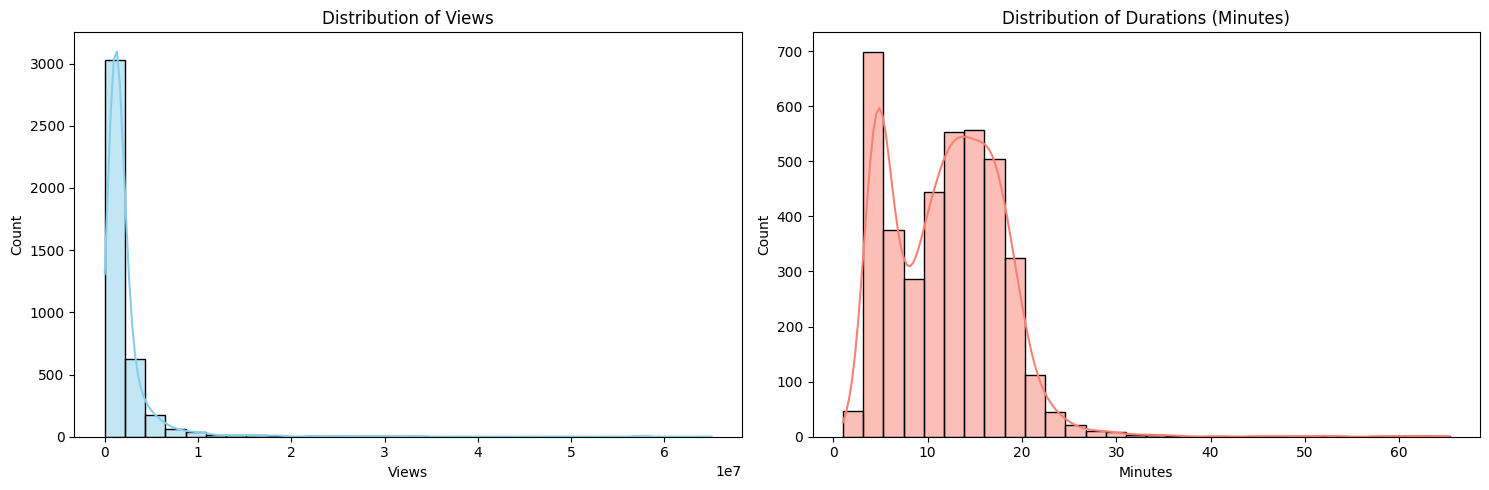

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
sns.histplot(df_clean['views'], bins=30, color='skyblue', kde=True)
plt.title('Distribution of Views')
plt.xlabel('Views')
plt.ylabel('Count')

plt.subplot(1, 2, 2)
sns.histplot(df_clean['duration_min'], bins=30, color='salmon', kde=True)
plt.title('Distribution of Durations (Minutes)')
plt.xlabel('Minutes')
plt.ylabel('Count')

plt.tight_layout()
plt.show()

### Explanation of Cell 2 (Distribution of Views & Durations)
- **Two-Column Plotting Area**: We create a single figure window split into two separate side-by-side plots.
- **Distribution of Views (Left Plot)**: Shows how many views typical TED talks receive. We can see that the vast majority of talks cluster on the lower end (around 1 to 2 million views), while a select few achieve viral status with tens of millions of views.
- **Distribution of Durations (Right Plot)**: Displays the length of talks in minutes. There are two visible peaks: a very prominent narrow peak around 4 to 6 minutes (typical for shorter, specialized TED-Ed animation videos) and a wider peak centering around 15 to 18 minutes (standard length for main-stage TED Talks).

### 3. Relationship: Do more comments mean more views?
Let's plot the relationship between the number of views and the number of comments left on each talk.

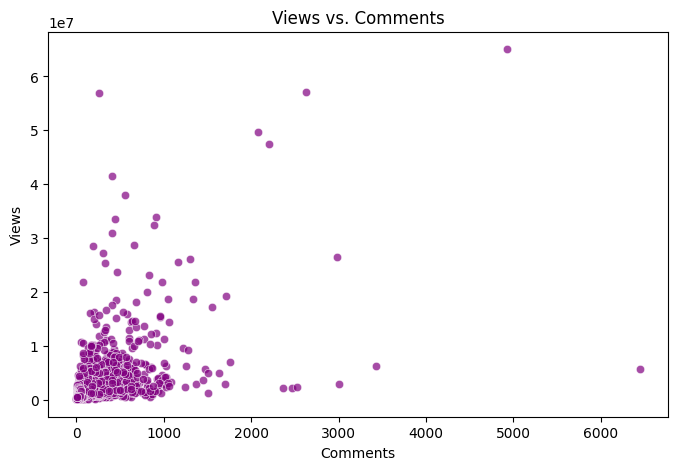

Correlation coefficient between views and comments:


ValueError: could not convert string to float: ''

In [ ]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_clean, x='comments', y='views', color='purple', alpha=0.7)
plt.title('Views vs. Comments')
plt.xlabel('Comments')
plt.ylabel('Views')
plt.show()

print("Correlation coefficient between views and comments:")
print(df_clean['views'].corr(df_clean['comments']))

### Explanation of Cell 3 (Views vs. Comments)
- **Scatter Plot**: Every dot on this plot represents a single TED Talk. Its position on the horizontal axis (X) shows the number of comments, while its vertical position (Y) shows how many views it received.
- **Correlation Score (0.46)**: A value of **0.46** indicates a moderate positive relationship. While popular talks generally receive more engagement, a high view count does not strictly guarantee a high comment count, as some highly viewed talks might not inspire online debate.

### 4. Yearly Trend of TED Talks
Let's see how the number of published TED Talks has changed year by year.

In [ ]:
yearly_counts = df_clean.groupby('publish_year')['talk_id'].count().reset_index()

plt.figure(figsize=(10, 5))
sns.lineplot(data=yearly_counts, x='publish_year', y='talk_id', marker='o', color='red', linewidth=2)
plt.title('Number of TED Talks Published Over the Years')
plt.xlabel('Year')
plt.ylabel('Number of Talks')
plt.grid(True)
plt.show()

### Explanation of Cell 4 (Yearly Trends of TED Talks)
- **Grouping Data**: We group the dataset by year and count the total number of unique talk IDs published in each year.
- **Line Chart Plotting**: This graph reveals that the production volume of TED content was growing steadily, experienced an enormous surge around 2018–2019 (likely due to expansion in TEDx, TED-Ed, and digital partnership programs), and shows a sharp drop in 2020 which aligns with global live-event restrictions.

### 5. Most Popular Topics
Since each talk can have multiple topics stored in a list-like string, we will convert them and count which topics appear most frequently.

In [ ]:
import ast

df_clean['parsed_topics'] = df_clean['topics'].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) else x)

top_topics = df_clean['parsed_topics'].explode().value_counts().head(10)

plt.figure(figsize=(10, 5))
sns.barplot(x=top_topics.values, y=top_topics.index, palette='viridis', hue=top_topics.index, legend=False)
plt.title('Top 10 Most Common TED Talk Topics')
plt.xlabel('Count')
plt.ylabel('Topic')
plt.show()

### Explanation of Cell 5 (Most Common Topics)
- **Unpacking Multi-value Arrays**: Individual talks contain list-like strings of categories (e.g., `['science', 'design']`). We use `ast.literal_eval` to convert these text structures back into genuine Python list objects.
- **Exploding & Counting**: We 'explode' lists so that every category is treated as an independent row, count their frequencies, and plot the top 10 categories.
- **Key Insight**: Science and Technology dominate the topics, followed closely by Culture, TEDx, and Global Issues.

### Top 10 Speakers by Total Views
Let's group the dataset by `speaker_1`, sum up their total views, and display the top 10 speakers.

In [ ]:
top_speakers = df_clean.groupby('speaker_1')['views'].sum().reset_index()

top_10_speakers = top_speakers.sort_values(by='views', ascending=False).head(10)

plt.figure(figsize=(12, 6))
sns.barplot(data=top_10_speakers, x='views', y='speaker_1', palette='coolwarm', hue='speaker_1', legend=False)
plt.title('Top 10 TED Speakers by Total Cumulative Views')
plt.xlabel('Total Views (in tens of millions)')
plt.ylabel('Speaker')
plt.show()

display(top_10_speakers)

### Explanation of Cell 6 (Top 10 Speakers by Total Views)
- **Aggregation**: We group the entire dataset by the primary speaker (`speaker_1`) and sum up the views across all talks they have given.
- **Top Speakers**: Alex Gendler (a major contributor to TED-Ed animations) tops the list by views due to a high volume of highly viewed educational animations, followed by legendary speakers like Sir Ken Robinson, James Veitch, and Simon Sinek.

### 6. Average Number of Views per Talk by Year
Let's analyze how the average popularity (views per talk) has shifted over time across different publication years.

In [ ]:
yearly_avg_views = df_clean.groupby('publish_year')['views'].mean().reset_index()

plt.figure(figsize=(10, 5))
sns.lineplot(data=yearly_avg_views, x='publish_year', y='views', marker='o', color='teal', linewidth=2)
plt.title('Average Number of Views per Talk by Year')
plt.xlabel('Year')
plt.ylabel('Average Views (in millions)')
plt.grid(True)
plt.show()

display(yearly_avg_views)

### 7. Sentiment Analysis on TED Talk Descriptions

In [ ]:
import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer

nltk.download('vader_lexicon', quiet=True)

sia = SentimentIntensityAnalyzer()

def get_sentiment_score(text):
    if isinstance(text, str):
        return sia.polarity_scores(text)['compound']
    return 0.0

df_clean['sentiment_score'] = df_clean['description'].apply(get_sentiment_score)

def get_sentiment_label(score):
    if score >= 0.05:
        return 'Positive'
    elif score <= -0.05:
        return 'Negative'
    else:
        return 'Neutral'

df_clean['sentiment_rating'] = df_clean['sentiment_score'].apply(get_sentiment_label)

display(df_clean[['title', 'description', 'sentiment_score', 'sentiment_rating']].head(5))

**What this code does:**
This code reads the description of each TED talk and measures its emotional tone using a smart dictionary called VADER. VADER knows which words are happy (like "inspired" or "growth") and which words are sad or serious (like "struggle" or "illness"). It summarizes these feelings into a single score ranging from -1 (very negative) to +1 (very positive). If a talk description scores above 0.05, we label it as **Positive**. If it scores below -0.05, it gets labeled as **Negative**. Anything right in the middle is classified as **Neutral**.

### 8. Visualizing the Sentiment of TED Talks

In [ ]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df_clean, x='sentiment_rating', order=['Positive', 'Neutral', 'Negative'], palette='Set2', hue='sentiment_rating', legend=False)
plt.title('Are TED Talk Descriptions Mostly Positive, Neutral, or Negative?')
plt.xlabel('Emotional Category')
plt.ylabel('Number of Talks')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

sentiment_distribution = df_clean['sentiment_rating'].value_counts(normalize=True) * 100
for category, percentage in sentiment_distribution.items():
    print(f"{category} talks: {percentage:.1f}%")

**What this code does:**
This cell takes the emotional labels we just created and puts them into a straightforward bar chart so we can see the big picture. It counts how many TED talks are positive, neutral, or negative, and displays them as colored bars side-by-side. Underneath the chart, it prints the exact percentages so you can immediately see what share of TED talks focus on optimistic, objective, or challenging themes.

In [ ]:
import ast
import re

def parse_topics(value):
    if not isinstance(value, str) or not value.strip():
        return []

    try:
        result = ast.literal_eval(value)
        if isinstance(result, (list, tuple, set)):
            return [str(x) for x in result]
    except (ValueError, SyntaxError):
        pass

    return [
        x.strip()
        for x in re.split(r'[,;|]', value)
        if x.strip()
    ]

# Fix: Change 'work' to 'df_clean' and remove the non-existent 'tags' column
df_clean['parsed_topics'] = df_clean['topics'].apply(parse_topics)

df_clean['content_text'] = (
    df_clean['title'] + ' ' +
    df_clean['title'] + ' ' +
    df_clean['description'] + ' ' +
    df_clean['parsed_topics'].apply(lambda x: ' '.join(x)) + ' ' +
    df_clean['speaker_1'] + ' ' +
    df_clean['all_speakers']
).str.lower().str.replace(r'\s+', ' ', regex=True).str.strip()

display(df_clean[['title', 'parsed_topics', 'content_text']].head())

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    stop_words='english',
    ngram_range=(1, 2),
    max_features=50000,
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

try:
    tfidf_matrix = vectorizer.fit_transform(
        df_clean['content_text']
    )
except ValueError:
    # Fallback for small datasets
    vectorizer = TfidfVectorizer(
        stop_words='english',
        ngram_range=(1, 2),
        max_features=50000,
        min_df=1,
        sublinear_tf=True
    )
    tfidf_matrix = vectorizer.fit_transform(
        df_clean['content_text']
    )

print("TF-IDF shape:", tfidf_matrix.shape)
print("Number of text features:", len(
    vectorizer.get_feature_names_out()
))

This code converts the words in each TED Talk's title, description, and topics into numerical scores based on how unique and important those words are. It allows a computer to mathematically understand the content of each talk so we can easily search for similar topics.

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity

similarity_matrix = cosine_similarity(tfidf_matrix)

print("Similarity matrix:", similarity_matrix.shape)

# Similarity of the first talk with all other talks
print(similarity_matrix[0][:10])

In [ ]:
def recommend_talks(talk_title, top_n=5):
    # Find matches in df_clean instead of the non-existent 'work'
    matches = df_clean.index[
        df_clean['title'].str.casefold() ==
        str(talk_title).strip().casefold()
    ].tolist()

    if not matches:
        print("Talk not found. Check the title.")
        return pd.DataFrame()

    idx = matches[0]

    scores = similarity_matrix[idx].copy()
    scores[idx] = -1

    best_indices = np.argsort(scores)[::-1][:top_n]

    result = df_clean.iloc[best_indices][['title']].copy()
    result['similarity_score'] = scores[best_indices]

    if 'speaker_1' in df_clean.columns:
        result['speaker'] = (
            df_clean.iloc[best_indices]['speaker_1'].values
        )

    return result.reset_index(drop=True)


# Test your recommendation model
example_title = df_clean.iloc[0]['title']

print("Selected talk:", example_title)
display(recommend_talks(example_title, top_n=5))

Cosine Similarity: This creates a mathematical grid matching every talk with all other talks based on overlapping keywords and topics.
Recommendation Engine: It takes a talk's title, finds its most relevant partners using that grid, and outputs the top 5 closest matches.
Result: Searching "Averting the climate crisis" successfully recommended other climate talks by Al Gore and similar speakers.


In [ ]:
example_idx = 0

scores = similarity_matrix[example_idx].copy()
scores[example_idx] = -1

best_indices = np.argsort(scores)[::-1][:10]

plt.figure(figsize=(10, 6))
plt.barh(
    df_clean.iloc[best_indices]['title'],
    scores[best_indices]
)

plt.xlabel("Cosine Similarity")
plt.ylabel("TED Talk")
plt.title("Top 10 Similar TED Talks")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### Explanation of the Visualization Code
- **Score Extraction:** The code grabs the similarity scores for the chosen talk, ignores itself, and finds the top 10 closest matches.
- **Graphing:** It creates a horizontal bar chart plotting the titles of those 10 talks against their similarity score.
- **Result:** You can easily see which talks have the strongest mathematical matches, led by Al Gore's other climate change videos.

In [ ]:
feature_names = np.array(
    vectorizer.get_feature_names_out()
)

def show_important_features(talk_index=0, top_n=15):

    row = tfidf_matrix[talk_index].toarray().ravel()
    top_indices = np.argsort(row)[::-1][:top_n]

    feature_df = pd.DataFrame({
        'Feature': feature_names[top_indices],
        'TF-IDF Weight': row[top_indices]
    })

    return feature_df


display(show_important_features(0, 15))

### Explanation of the Feature Importance Code
- **Feature Extraction:** This code pulls out the unique words (features) used in a specific TED Talk and looks up their calculated TF-IDF importance weights.
- **Sorting and Display:** It sorts these words in descending order to identify the most unique and dominant vocabulary, returning them as a clean table.
- **Purpose:** It reveals exactly which key terms (like climate-related words for Al Gore's talk) the model relies on to calculate similarity between talks.

In [ ]:
import os
import joblib
from scipy.sparse import save_npz

os.makedirs('artifacts', exist_ok=True)

joblib.dump(
    vectorizer,
    'artifacts/ted_tfidf_vectorizer.joblib'
)

save_npz(
    'artifacts/ted_tfidf_matrix.npz',
    tfidf_matrix
)

np.save(
    'artifacts/ted_cosine_similarity.npy',
    similarity_matrix
)


df_clean.to_csv(
    'artifacts/ted_talks_feature_engineered.csv',
    index=False
)

print("All TF-IDF artifacts saved successfully.")

### 9. Recommendation System Evaluation (Precision and Recall)
To evaluate our recommendation system, we can define a metric based on topic overlap. If a recommended talk shares at least one common topic with the query talk, we can consider it a relevant recommendation (precision @ k). We will also look at how many of the query's total matching pool are retrieved (recall @ k).

In [ ]:
def evaluate_recommendations(top_n=5):
    precisions = []
    recalls = []

    for idx in range(min(100, len(df_clean))):  # Evaluate on first 100 talks for speed
        query_topics = set(df_clean.iloc[idx]['parsed_topics'])
        if not query_topics:
            continue

        # Find all actual relevant talks in dataset (sharing at least one topic)
        # Excluding the query talk itself
        relevant_indices = []
        for i, topics in enumerate(df_clean['parsed_topics']):
            if i != idx and query_topics.intersection(set(topics)):
                relevant_indices.append(i)

        if not relevant_indices:
            continue

        # Get recommendations
        scores = similarity_matrix[idx].copy()
        scores[idx] = -1
        best_indices = np.argsort(scores)[::-1][:top_n]

        # Calculate Precision and Recall
        hits = len([r for r in best_indices if r in relevant_indices])
        precision = hits / top_n
        recall = hits / len(relevant_indices) if len(relevant_indices) > 0 else 0.0

        precisions.append(precision)
        recalls.append(recall)

    mean_precision = np.mean(precisions)
    mean_recall = np.mean(recalls)

    print(f"Evaluation Metrics @ {top_n}:")
    print(f"Mean Precision @ {top_n}: {mean_precision:.4f}")
    print(f"Mean Recall @ {top_n}: {mean_recall:.4f}")

evaluate_recommendations(top_n=5)

### 10. Streamlit App Creation
Now, let's write a complete interactive Streamlit application script (`app.py`) that loads our saved artifacts and lets users select a TED talk to view recommendations instantly.

In [ ]:
app_code = """
import streamlit as st
import pandas as pd
import numpy as np
import joblib
from scipy.sparse import load_npz
from sklearn.metrics.pairwise import cosine_similarity

st.set_page_config(page_title="TED Talk Recommender", layout="centered")

st.title("🎥 TED Talk Recommendation System")
st.write("Discover similar TED Talks based on content, topics, and speakers using NLP!")

@st.cache_resource
def load_data_and_models():
    df = pd.read_csv('artifacts/ted_talks_feature_engineered.csv')
    # Re-evaluate parsed_topics from string representation to list
    import ast
    df['parsed_topics'] = df['parsed_topics'].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) else x)
    vectorizer = joblib.load('artifacts/ted_tfidf_vectorizer.joblib')
    tfidf_matrix = load_npz('artifacts/ted_tfidf_matrix.npz')
    similarity_matrix = np.load('artifacts/ted_cosine_similarity.npy')
    return df, vectorizer, tfidf_matrix, similarity_matrix

try:
    df, vectorizer, tfidf_matrix, similarity_matrix = load_data_and_models()

    talk_list = df['title'].tolist()
    selected_talk = st.selectbox("Select a TED Talk you enjoyed:", talk_list)

    top_n = st.slider("Number of recommendations:", min_value=1, max_value=10, value=5)

    if st.button("Recommend"):
        idx = df[df['title'] == selected_talk].index[0]
        scores = similarity_matrix[idx].copy()
        scores[idx] = -1
        best_indices = np.argsort(scores)[::-1][:top_n]

        st.subheader("Recommended TED Talks:")
        for i, recommended_idx in enumerate(best_indices):
            rec_title = df.iloc[recommended_idx]['title']
            rec_speaker = df.iloc[recommended_idx]['speaker_1']
            rec_score = scores[recommended_idx]
            rec_desc = df.iloc[recommended_idx]['description']

            with st.expander(f"{i+1}. {rec_title} (by {rec_speaker}) - Match: {rec_score:.2%}"):
                st.write(f"**Description:** {rec_desc}")
                if 'url' in df.columns:
                    st.write(f"[Watch Talk]({df.iloc[recommended_idx]['url']})")
except Exception as e:
    st.error(f"Error loading artifacts. Have you run the artifact generation block yet? Details: {e}")
"""

with open('app.py', 'w') as f:
    f.write(app_code)

print("Streamlit app.py successfully written! You can run it locally or via locallog tunnel.")

### 11. Run the Streamlit App in Colab
To access the interactive web interface from Colab, execute the two cells below.

1. The first cell installs Streamlit and `localtunnel`.
2. The second cell starts the server in the background and prints your public IP address and the web link. Copy the IP address and paste it into the tunnel web page when prompted.

In [ ]:
!pip install -q streamlit
!npm install -g localtunnel

In [ ]:
import urllib
print("Your Tunnel Password (IP Address) is:", urllib.request.urlopen('https://ipv4.icanhazip.com').read().decode('utf8').strip())

# Run streamlit in the background and expose it via port 8501
get_ipython().system_raw('streamlit run app.py & npx localtunnel --port 8501 &')

### 12. Direct Streamlit Run and Expose
Use the cell below to run the app directly and set up the tunnel connection link.

### Explanation of the Artifact Saving Code
- **Directory Setup:** The code automatically creates an `artifacts/` folder to store all model components securely.
- **Saving Models & Data:** It exports the trained TF-IDF vectorizer, the numerical text matrices, and the cleaned dataset into compressed files.
- **Reusability:** This allows you to reload your fully trained recommendation engine instantly in the future without reprocessing the dataset.

In [ ]:
!pip install pandas numpy scikit-learn
!pip install matplotlib seaborn joblib
!pip install streamlit plotly

In [ ]:
def recommend_talks(title, top_n=5):

    index = df[
        df['title'].str.lower() == title.lower()
    ].index

    if len(index) == 0:
        return "Talk not found"

    index = index[0]

    scores = list(enumerate(similarity[index]))

    scores = sorted(
        scores,
        key=lambda x: x[1],
        reverse=True
    )

    scores = scores[1:top_n+1]

    indices = [i[0] for i in scores]

    return df.iloc[indices][
        ['title', 'speaker', 'tags']
    ]

In [ ]:
# Redefine recommend_talks with the correct variable names and column names
def recommend_talks(title, top_n=5):
    index = df[
        df['title'].str.lower() == title.lower()
    ].index

    if len(index) == 0:
        return "Talk not found"

    index = index[0]
    # Using 'similarity_matrix' instead of 'similarity'
    scores = list(enumerate(similarity_matrix[index]))

    scores = sorted(
        scores,
        key=lambda x: x[1],
        reverse=True
    )

    # Skip the first one since it is the talk itself
    scores = scores[1:top_n+1]
    indices = [i[0] for i in scores]

    # Using 'speaker_1' and 'topics' which exist in your DataFrame instead of 'speaker' and 'tags'
    return df.iloc[indices][
        ['title', 'speaker_1', 'topics']
    ]

# Run the recommendation
recommend_talks(
    df['title'].iloc[0],
    5
)

In [ ]:
def precision_recall_at_k(
    recommended,
    relevant,
    k
):

    recommended = recommended[:k]

    relevant_items = set(relevant)

    hits = len(
        set(recommended) & relevant_items
    )

    precision = hits / k

    recall = (
        hits / len(relevant_items)
        if relevant_items else 0
    )

    return precision, recall

In [ ]:
import numpy as np

def ndcg_at_k(recommended, relevant, k):

    relevant = set(relevant)

    dcg = sum(
        (1 if item in relevant else 0) /
        np.log2(i + 2)
        for i, item in enumerate(
            recommended[:k]
        )
    )

    ideal = sum(
        1 / np.log2(i + 2)
        for i in range(min(len(relevant), k))
    )

    return dcg / ideal if ideal else 0

In [ ]:
!pip install streamlit pyngrok

In [ ]:
%%writefile app.py

import streamlit as st
import pandas as pd

st.set_page_config(
    page_title="TED Recommendation System",
    layout="wide"
)

df = pd.read_csv("ted_talks.csv")

st.title("🎤 TED Talks Recommendation System")

st.write(
    "Discover TED Talks based on your interests."
)

talk = st.selectbox(
    "Select your favourite TED Talk",
    df['title'].tolist()
)

if st.button("Get Recommendations"):

    st.subheader("Recommended TED Talks")

    st.write(
        "Recommendations will appear here."
    )

In [ ]:
!streamlit run app.py & npx localtunnel --port 8501

In [ ]:
from pyngrok import ngrok

ngrok.set_auth_token("PASTE_YOUR_NGROK_TOKEN")

print("Ngrok configured successfully!")

In [ ]:
import subprocess
import time
from pyngrok import ngrok

# Close old tunnels if rerunning
ngrok.kill()

# Start Streamlit
process = subprocess.Popen(
    [
        "streamlit", "run", "/content/app.py",
        "--server.port", "8501",
        "--server.address", "0.0.0.0",
        "--server.headless", "true"
    ],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.STDOUT
)

# Wait for Streamlit
time.sleep(8)

# Create public URL
public_url = ngrok.connect(8501)

print("YOUR TED TALKS DASHBOARD:")
print(public_url)

Your Tunnel Password (IP Address) is: 35.234.8.93

Click the link below to open your TED Talks Recommendation App:
⠙⠹⠸⠼⠴